In [33]:
import numpy as np
import matplotlib.pyplot as plt

import cec2017.functions as cec
import cec2017.utils as utils

In [34]:
def set_random_seed(seed):
    np.random.seed(seed)
set_random_seed(179971)

In [35]:
BOTTOM_BORDER = -100
TOP_BORDER = 100
DIM = 10

In [36]:
class Particle:
    def __init__(self, dim, f, w, c1, c2):
        self.f = f
        self.w = w
        self.c1 = c1
        self.c2 = c2
        self.velocity_limit = (TOP_BORDER - BOTTOM_BORDER)
        self.x = np.random.uniform(BOTTOM_BORDER, TOP_BORDER, dim)
        self.v = np.random.uniform(-self.velocity_limit, self.velocity_limit, dim)
        self.p = self.x.copy()
        self.best_value = float(f(self.p[None, :])[0])
        self.log = [self.best_value]

    def step(self, g):
        rp = np.random.uniform(0, 1, self.x.size)
        rg = np.random.uniform(0, 1, self.x.size)
        self.v = self.w * self.v + self.c1 * rp * (self.p - self.x) + self.c2 * rg * (g - self.x)
        self.v = np.clip(self.v, -self.velocity_limit, self.velocity_limit)
        self.x = np.clip(self.x + self.v, BOTTOM_BORDER, TOP_BORDER)
        value = float(self.f(self.x[None, :])[0])
        if value < self.best_value:
            self.best_value = value
            self.p = self.x.copy()
        self.log.append(self.best_value)
        return self.best_value, self.p

class Swarm:
    def __init__(self, cnt, dim, f, w, c1, c2):
        self.swarm = [Particle(dim, f, w, c1, c2) for _ in range(cnt)]
        best = min(self.swarm, key=lambda particle: particle.best_value)
        self.g = best.p.copy()
        self.best_value = best.best_value
        self.log = [self.best_value]
    
    def step(self):
        for particle in self.swarm:
            cur_val, cur = particle.step(self.g)
            if cur_val < self.best_value:
                self.best_value = cur_val
                self.g = cur.copy()
        self.log.append(self.best_value)
    
    def run(self, iterations):
        for _ in range(iterations):
            self.step()
        return self.best_value, self.g

f1: value=1489.374309991723, error=1389.374309991723


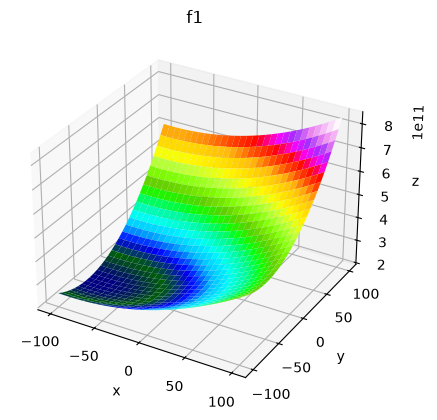

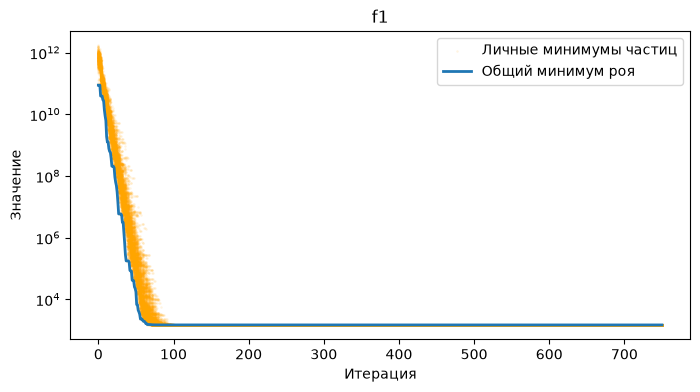

f3: value=300.0, error=0.0


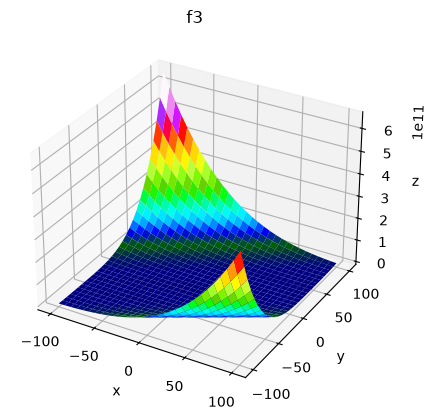

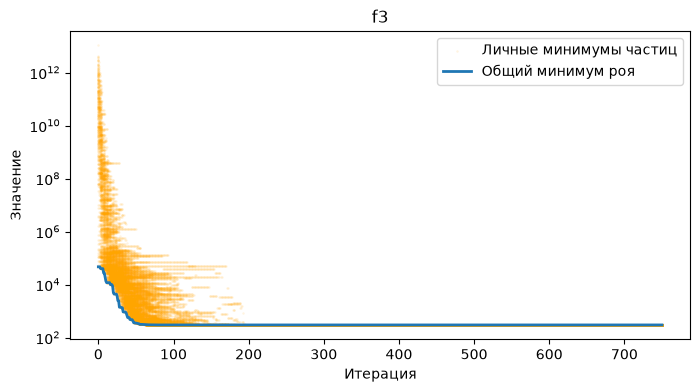

f4: value=400.022154057299, error=0.022154057299019314


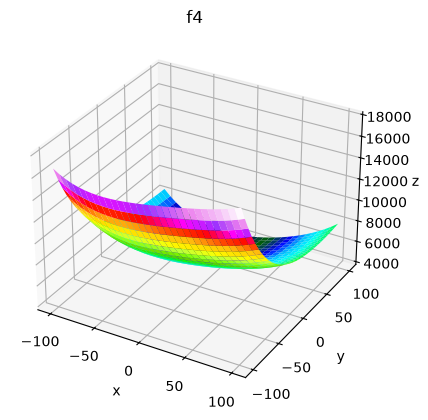

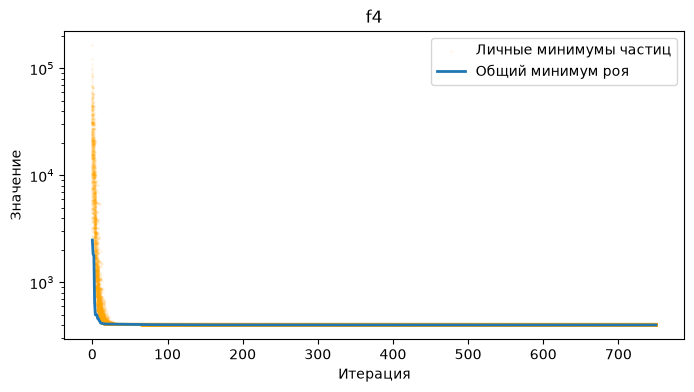

f5: value=521.2194803654811, error=21.219480365481104


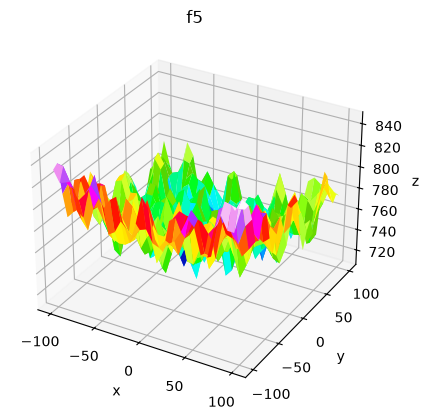

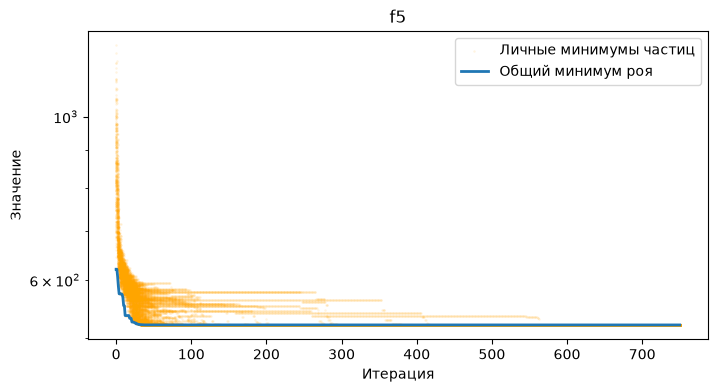

f6: value=609.724433250943, error=9.72443325094298


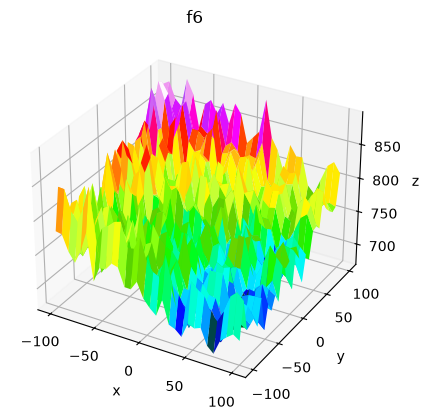

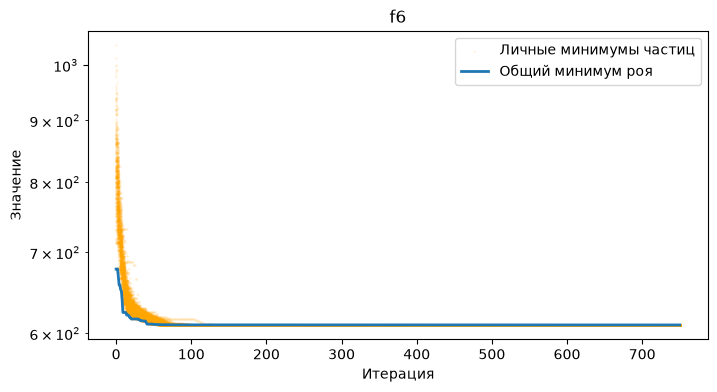

f7: value=717.0440325771585, error=17.044032577158532


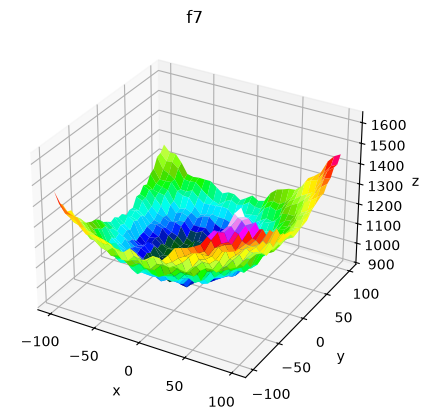

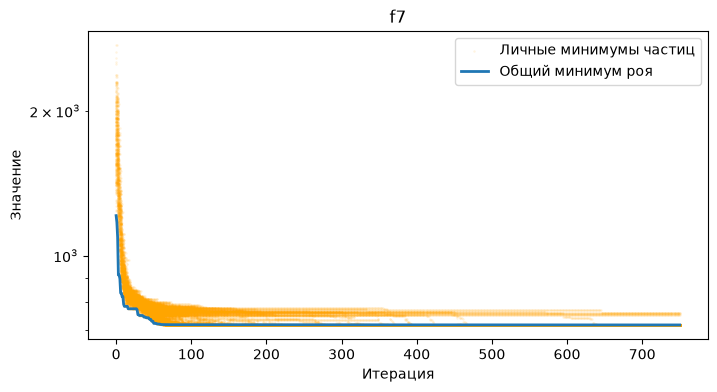

f8: value=810.9445445902071, error=10.944544590207101


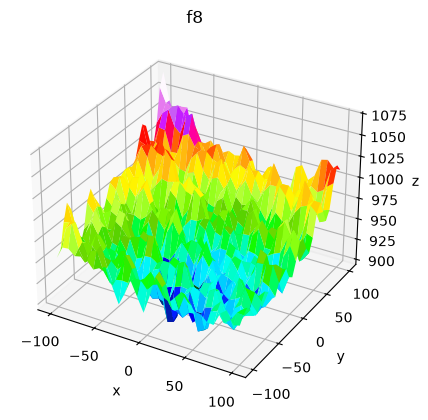

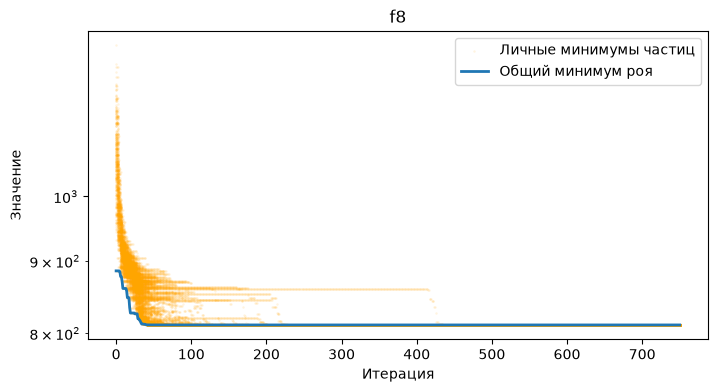

f9: value=900.0, error=0.0


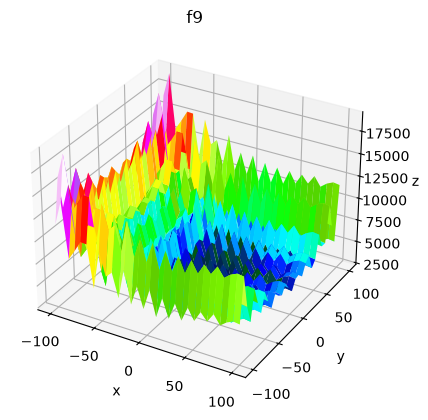

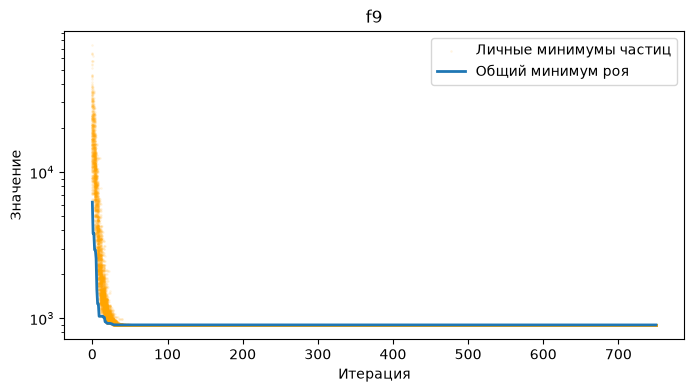

f10: value=1434.8146130856194, error=434.8146130856194


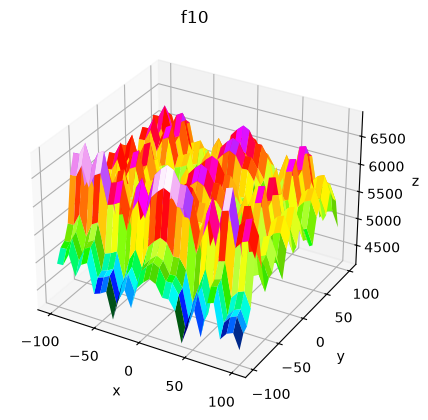

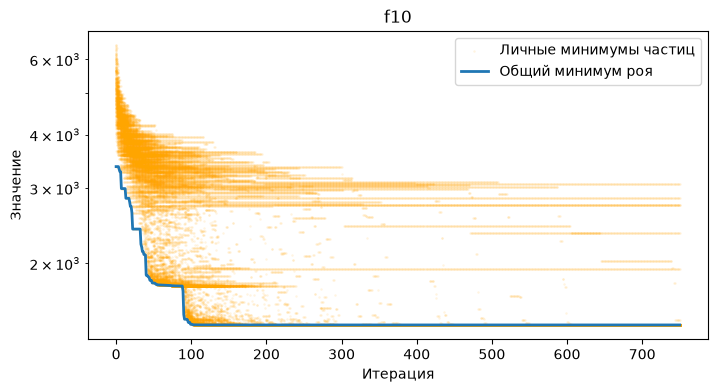

f11: value=1141.7979689125286, error=41.79796891252863


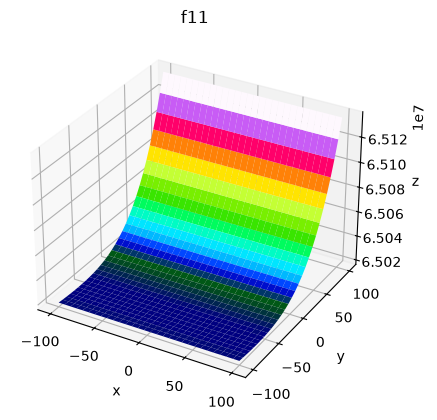

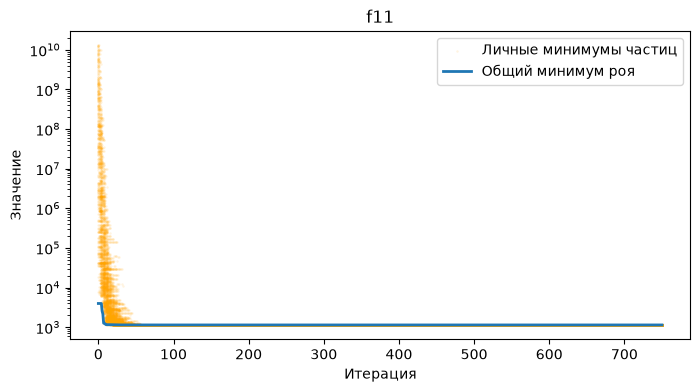

f12: value=6620.616774684164, error=5420.616774684164


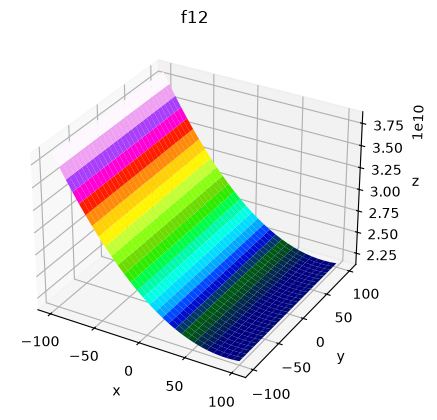

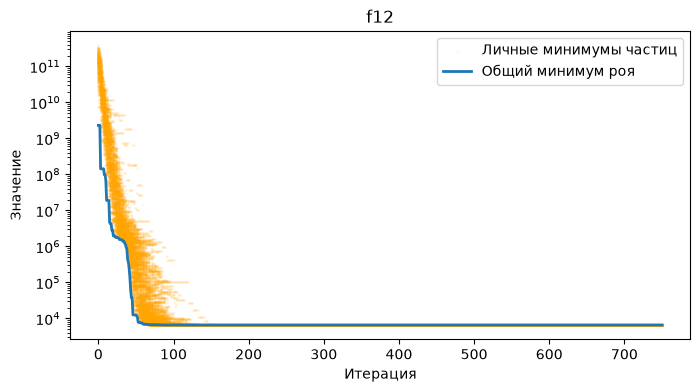

f13: value=8086.786011504782, error=6786.786011504782


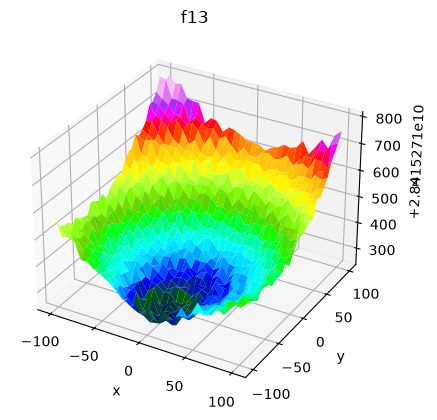

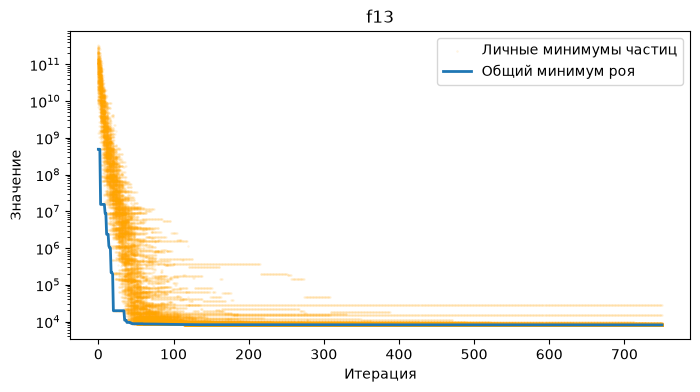

f14: value=1569.0273506370977, error=169.0273506370977


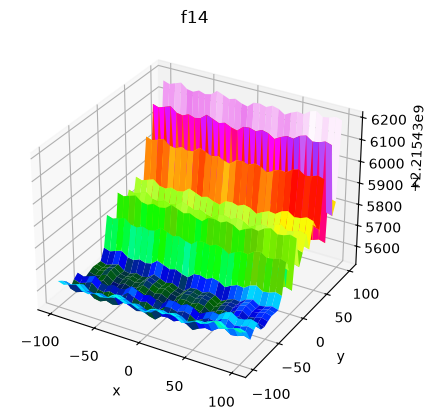

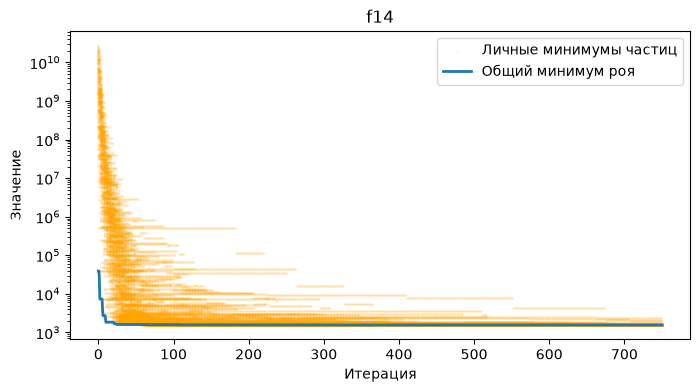

f15: value=1551.6921822154186, error=51.6921822154186


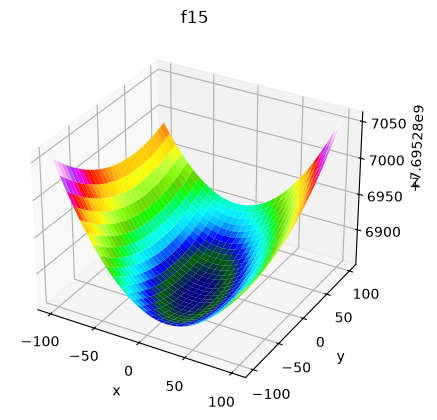

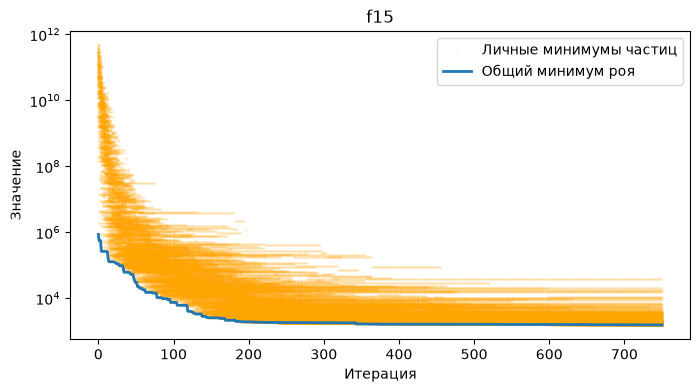

f16: value=1855.3916947717564, error=255.39169477175642


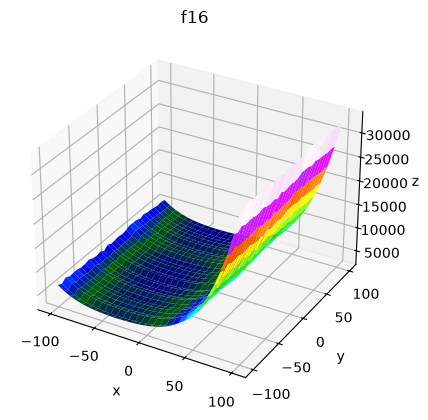

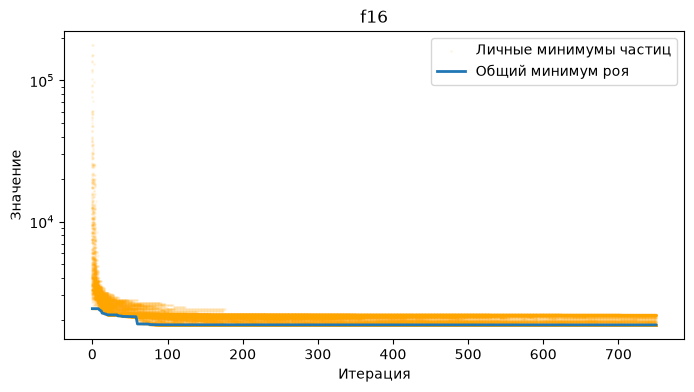

f17: value=1754.4138323610475, error=54.413832361047525


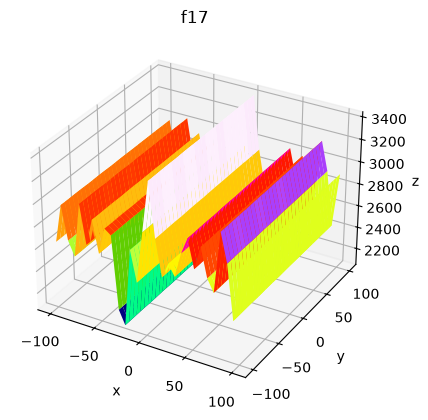

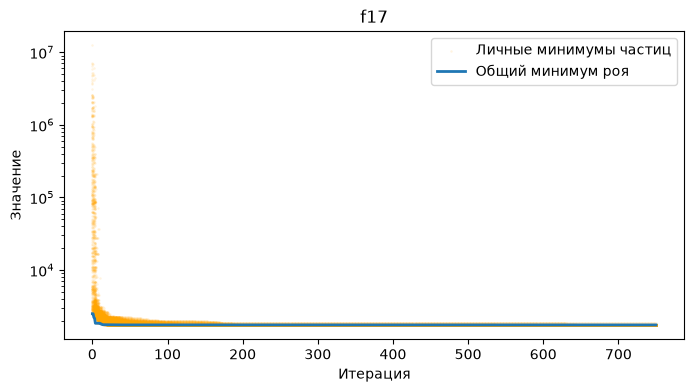

f18: value=33682.712431930486, error=31882.712431930486


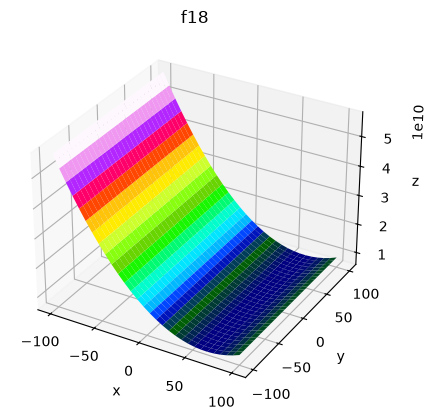

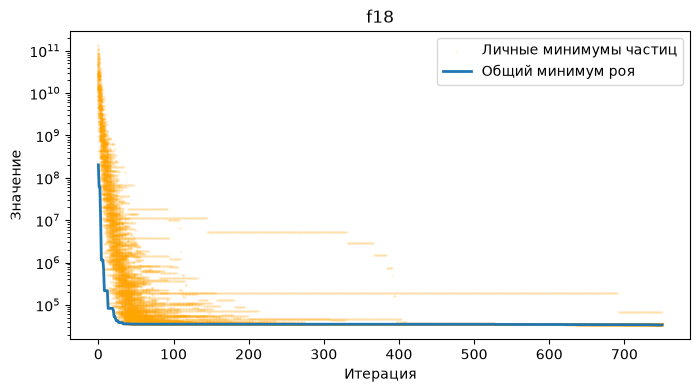

f19: value=10565.289703309702, error=8665.289703309702


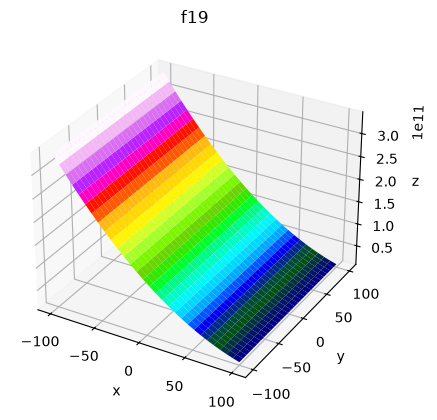

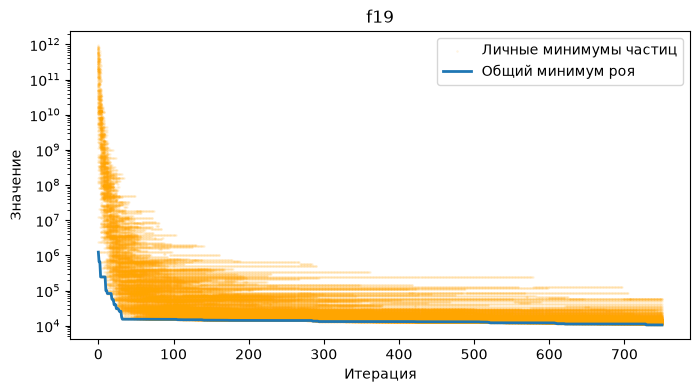

f20: value=2027.2879717367464, error=27.287971736746385


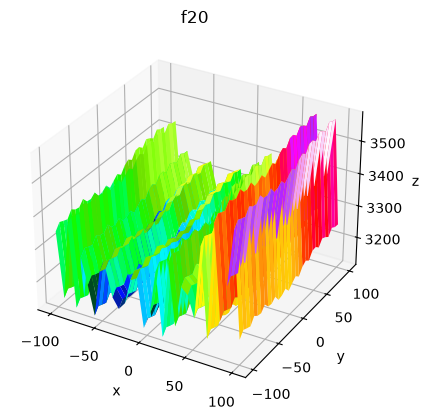

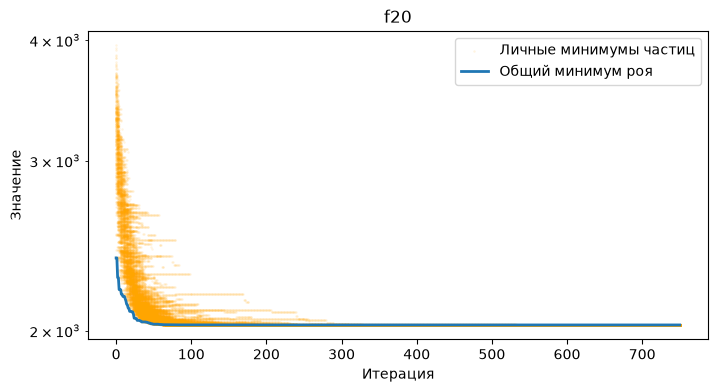

f21: value=2322.1009175337235, error=222.10091753372353


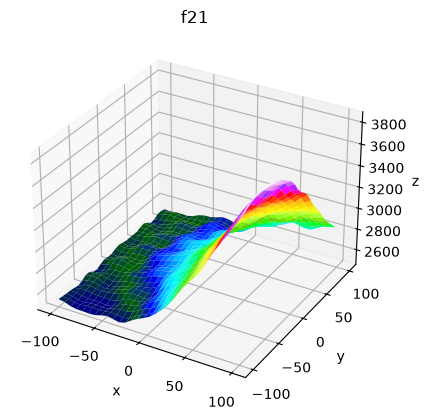

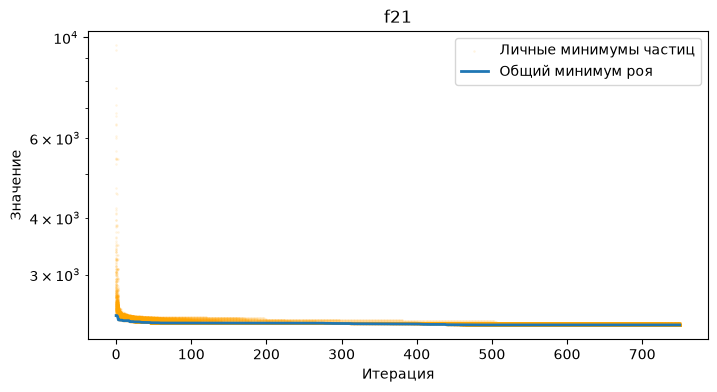

f22: value=2313.7764915374305, error=113.7764915374305


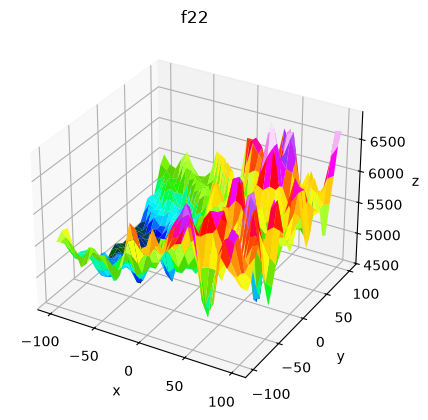

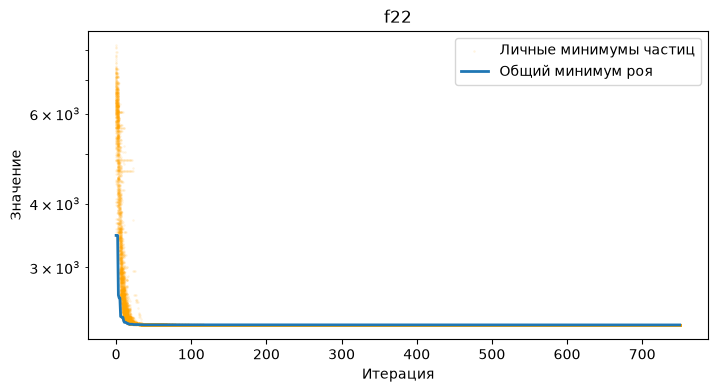

f23: value=2610.8188697764595, error=310.81886977645945


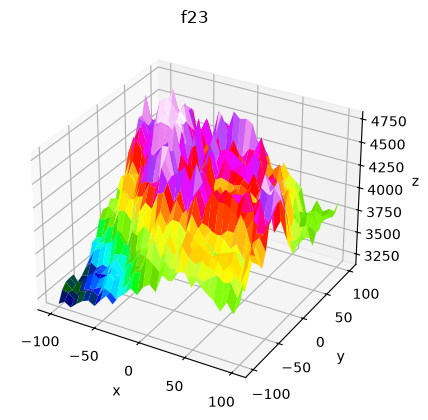

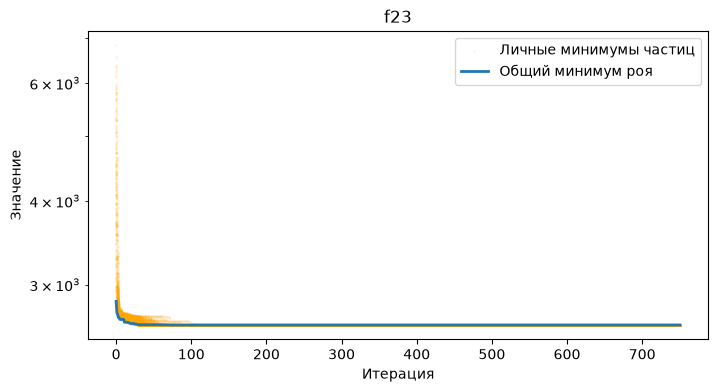

f24: value=2752.2732566072527, error=352.27325660725273


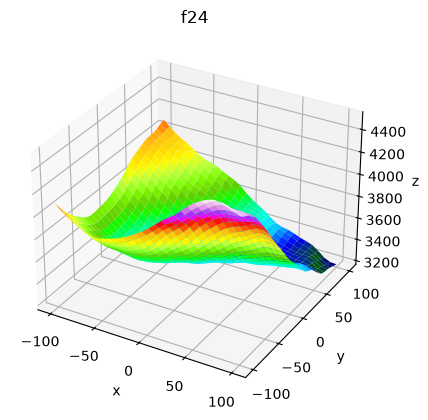

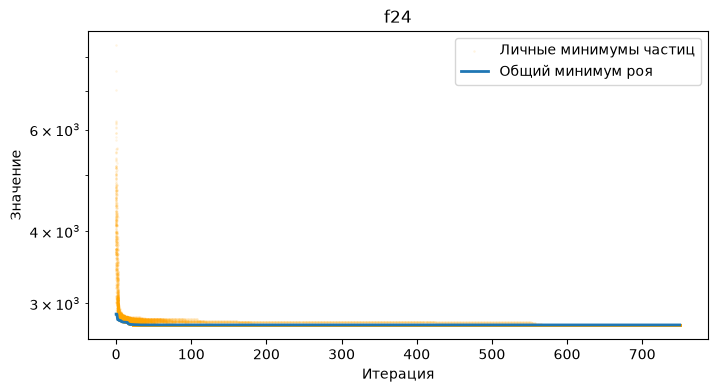

f25: value=2951.72753512932, error=451.72753512932013


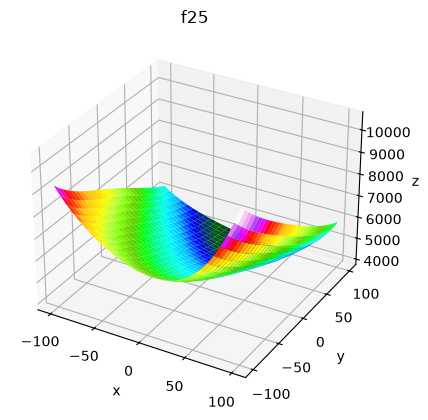

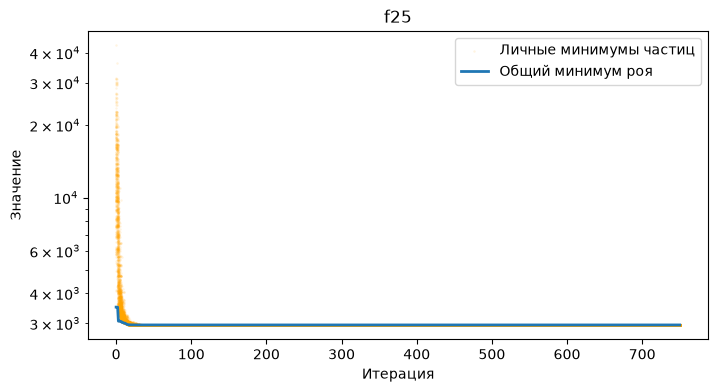

f26: value=3028.315061823384, error=428.315061823384


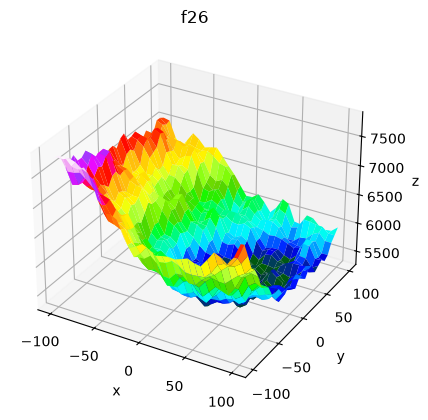

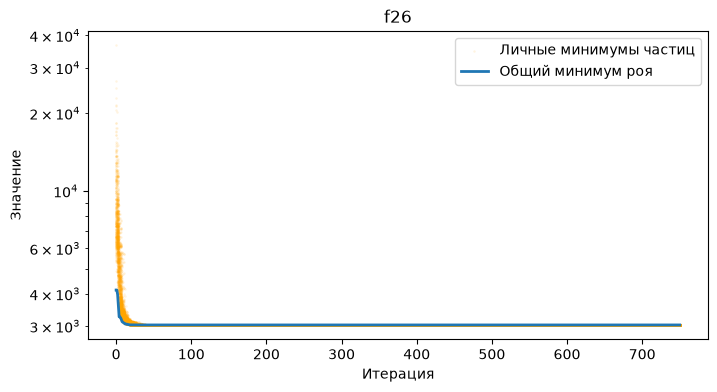

f27: value=3097.216463535684, error=397.21646353568394


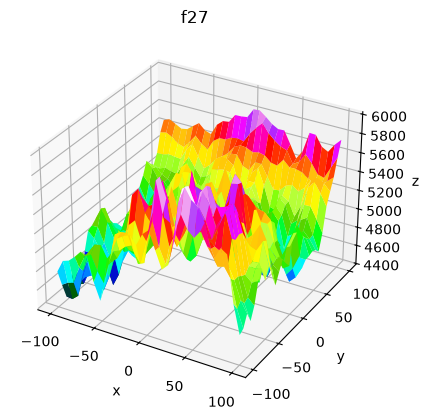

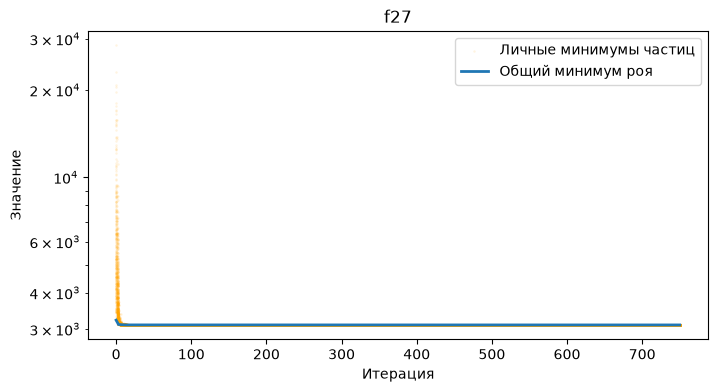

f28: value=3411.8886308937135, error=611.8886308937135


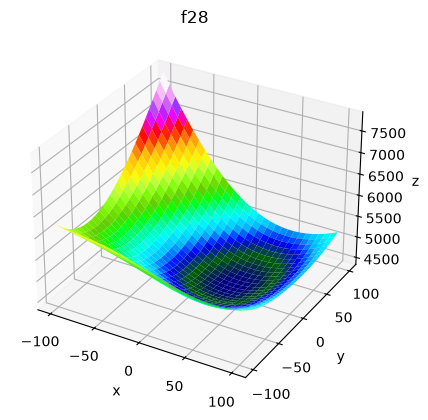

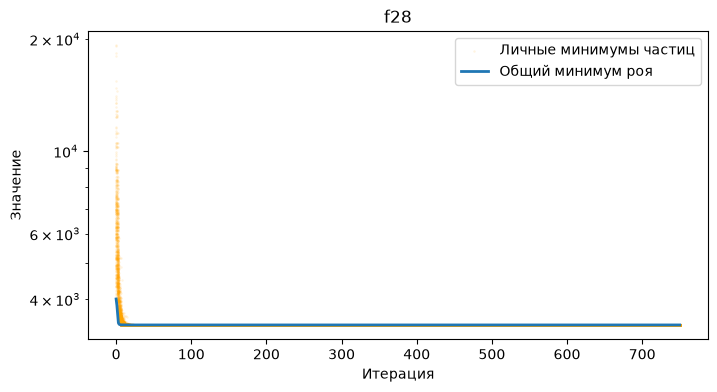

f29: value=3255.0051923944548, error=355.00519239445475


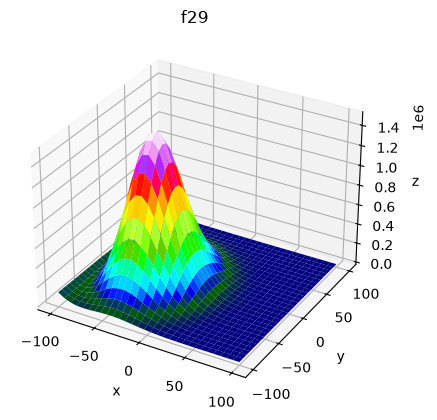

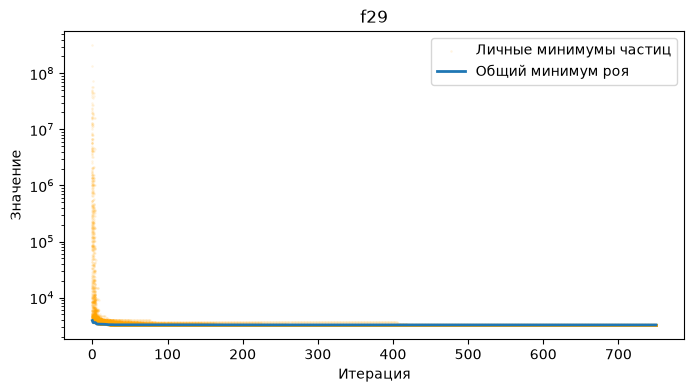

f30: value=6418.555169693791, error=3418.555169693791


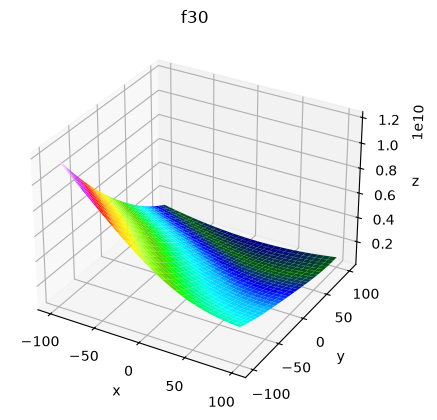

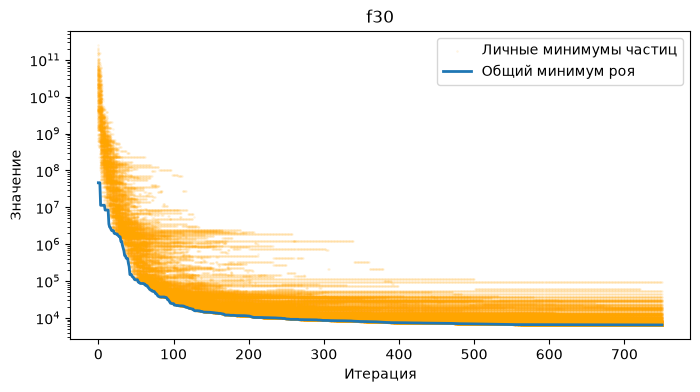

In [37]:
for i in range(len(cec.all_functions)):
    f = cec.all_functions[i]
    if f is cec.f2:
        continue
    s = Swarm(250, DIM, f, 0.7, 1, 1)
    val, cord = s.run(750)
    optimum = 100 * (i + 1)
    print(f"f{i + 1}: value={val}, error={val - optimum}")
    utils.surface_plot(f, dimension=DIM)
    fig, ax = plt.subplots(figsize=(8, 4))
    particle_values = np.array([particle.log for particle in s.swarm])
    iterations = np.arange(len(s.log))
    ax.scatter(
        np.tile(iterations, len(s.swarm)), particle_values.ravel(),
        s=3, alpha=0.12, color="orange", linewidths=0,
        label="Личные минимумы частиц",
    )
    ax.plot(iterations, s.log, linewidth=2,
            label="Общий минимум роя")
    ax.set_yscale("log")
    ax.set(xlabel="Итерация", ylabel="Значение",
           title=f"f{i + 1}")
    ax.legend()
    plt.show()
    plt.close(fig)
    